# PUBG Game Winner Prediction (PRCP-1012)

**Goal:** Analyze PUBG match data and predict `winPlacePerc` (the final placement percentile), then compare regression models and identify important features.

This notebook follows the uploaded project brief: data analysis, prediction, model comparison, production-model recommendation, and challenges/solutions.

> The project ZIP is downloaded from the dataset link in the brief. If downloading fails, download the ZIP manually and set `ZIP_PATH` in the loading cell.

## 1. Install and import libraries

In [1]:
# Run this cell if the required packages are not installed.
%pip install -q pandas numpy matplotlib seaborn scikit-learn requests

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import zipfile
import glob
import warnings
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupShuffleSplit, train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
import joblib

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
RANDOM_STATE = 42

## 2. Select and load the PUBG training CSV

Choose the extracted `train_V2.csv` file from your computer. This avoids the corrupted ZIP download problem.

In [3]:
import os
import pandas as pd
try:
    import tkinter as tk
    from tkinter import filedialog

    root = tk.Tk()
    root.withdraw()
    root.attributes("-topmost", True)
    TRAIN_PATH = filedialog.askopenfilename(
        title="Select PUBG train_V2.csv",
        filetypes=[("CSV files", "*.csv"), ("All files", "*.*")]
    )
    root.destroy()
except Exception:
    TRAIN_PATH = ""
if not TRAIN_PATH:
    TRAIN_PATH = input(
        r"Enter full path to train_V2.csv (example: C:\Users\YourName\Downloads\train_V2.csv): "
    ).strip().strip('"')

if not os.path.isfile(TRAIN_PATH):
    raise FileNotFoundError(
        f"CSV file not found: {TRAIN_PATH}. Extract the Kaggle ZIP first, then select train_V2.csv."
    )

df = pd.read_csv(TRAIN_PATH)
print("Dataset loaded successfully!")
print("File:", TRAIN_PATH)
print("Dataset shape:", df.shape)
display(df.head())

Dataset loaded successfully!
File: E:/pubg/train_V2.csv
Dataset shape: (4446966, 29)


,Id,groupId,matchId,assists,boosts,damageDealt,DBNOs,headshotKills,heals,killPlace,killPoints,kills,killStreaks,longestKill,matchDuration,matchType,maxPlace,numGroups,rankPoints,revives,rideDistance,roadKills,swimDistance,teamKills,vehicleDestroys,walkDistance,weaponsAcquired,winPoints,winPlacePerc
0,7f96b2f878858a,4d4b580de459be,a10357fd1a4a91,0,0,0.00,0,0,0,60,1241,0,0,0.00,1306,squad-fpp,28,26,-1,0,0.0000,0,0.00,0,0,244.80,1,1466,0.4444
1,eef90569b9d03c,684d5656442f9e,aeb375fc57110c,0,0,91.47,0,0,0,57,0,0,0,0.00,1777,squad-fpp,26,25,1484,0,0.0045,0,11.04,0,0,1434.00,5,0,0.6400
2,1eaf90ac73de72,6a4a42c3245a74,110163d8bb94ae,1,0,68.00,0,0,0,47,0,0,0,0.00,1318,duo,50,47,1491,0,0.0000,0,0.00,0,0,161.80,2,0,0.7755
3,4616d365dd2853,a930a9c79cd721,f1f1f4ef412d7e,0,0,32.90,0,0,0,75,0,0,0,0.00,1436,squad-fpp,31,30,1408,0,0.0000,0,0.00,0,0,202.70,3,0,0.1667
4,315c96c26c9aac,de04010b3458dd,6dc8ff871e21e6,0,0,100.00,0,0,0,45,0,1,1,58.53,1424,solo-fpp,97,95,1560,0,0.0000,0,0.00,0,0,49.75,2,0,0.1875


## 3. Initial data inspection

In [4]:
print("Shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.to_frame("dtype"))

print("\nMissing values (top 20):")
display(df.isna().sum().sort_values(ascending=False).head(20).to_frame("missing_count"))

print("\nDuplicate rows:", df.duplicated().sum())
display(df.describe(include="all").T.head(40))

Shape: (4446966, 29)

Column names:
['Id', 'groupId', 'matchId', 'assists', 'boosts', 'damageDealt', 'DBNOs', 'headshotKills', 'heals', 'killPlace', 'killPoints', 'kills', 'killStreaks', 'longestKill', 'matchDuration', 'matchType', 'maxPlace', 'numGroups', 'rankPoints', 'revives', 'rideDistance', 'roadKills', 'swimDistance', 'teamKills', 'vehicleDestroys', 'walkDistance', 'weaponsAcquired', 'winPoints', 'winPlacePerc']

Data types:


,dtype
Id,object
groupId,object
matchId,object
assists,int64
boosts,int64
damageDealt,float64
DBNOs,int64
headshotKills,int64
heals,int64
killPlace,int64



Missing values (top 20):


,missing_count
winPlacePerc,1
matchType,0
winPoints,0
weaponsAcquired,0
walkDistance,0
vehicleDestroys,0
teamKills,0
swimDistance,0
roadKills,0
rideDistance,0



Duplicate rows: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Id,4446966,4446966,7f96b2f878858a,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
groupId,4446966,2026745,14d6b54cdec6bc,74,NaN,NaN,NaN,NaN,NaN,NaN,NaN
matchId,4446966,47965,4b5db40aec4797,100,NaN,NaN,NaN,NaN,NaN,NaN,NaN
assists,4446966.0,NaN,NaN,NaN,0.233815,0.588573,0.0,0.0,0.0,0.0,22.0
boosts,4446966.0,NaN,NaN,NaN,1.106908,1.715794,0.0,0.0,0.0,2.0,33.0
damageDealt,4446966.0,NaN,NaN,NaN,130.717138,170.780621,0.0,0.0,84.24,186.0,6616.0
DBNOs,4446966.0,NaN,NaN,NaN,0.657876,1.145743,0.0,0.0,0.0,1.0,53.0
headshotKills,4446966.0,NaN,NaN,NaN,0.22682,0.602155,0.0,0.0,0.0,0.0,64.0
heals,4446966.0,NaN,NaN,NaN,1.370147,2.679982,0.0,0.0,0.0,2.0,80.0
killPlace,4446966.0,NaN,NaN,NaN,47.59935,27.462937,1.0,24.0,47.0,71.0,101.0


## 4. Data cleaning

In [25]:
# The target column is required for supervised training.
TARGET = "winPlacePerc"
if TARGET not in df.columns:
    raise ValueError(
        f"Target column '{TARGET}' is missing. Make sure you loaded the training CSV, not the test CSV."
    )
df = df.dropna(subset=[TARGET]).copy()
df = df[df[TARGET].between(0, 1)].copy()
df = df.drop_duplicates().reset_index(drop=True)
print("Cleaned shape:", df.shape)
print("Target summary:")
display(df[TARGET].describe())

Cleaned shape: (4446965, 29)
Target summary:


count    4.446965e+06
mean     4.728216e-01
std      3.074050e-01
min      0.000000e+00
25%      2.000000e-01
50%      4.583000e-01
75%      7.407000e-01
max      1.000000e+00
Name: winPlacePerc, dtype: float64

## 5. Exploratory Data Analysis (EDA)

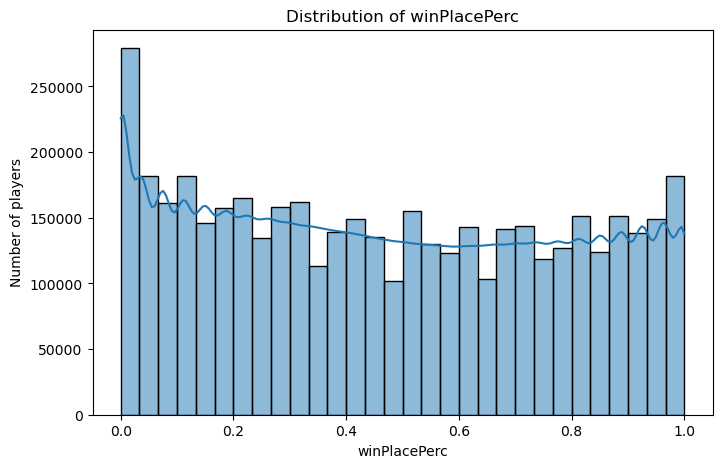

In [7]:
plt.figure(figsize=(8, 5))
sns.histplot(df[TARGET], bins=30, kde=True)
plt.title("Distribution of winPlacePerc")
plt.xlabel("winPlacePerc")
plt.ylabel("Number of players")
plt.show()

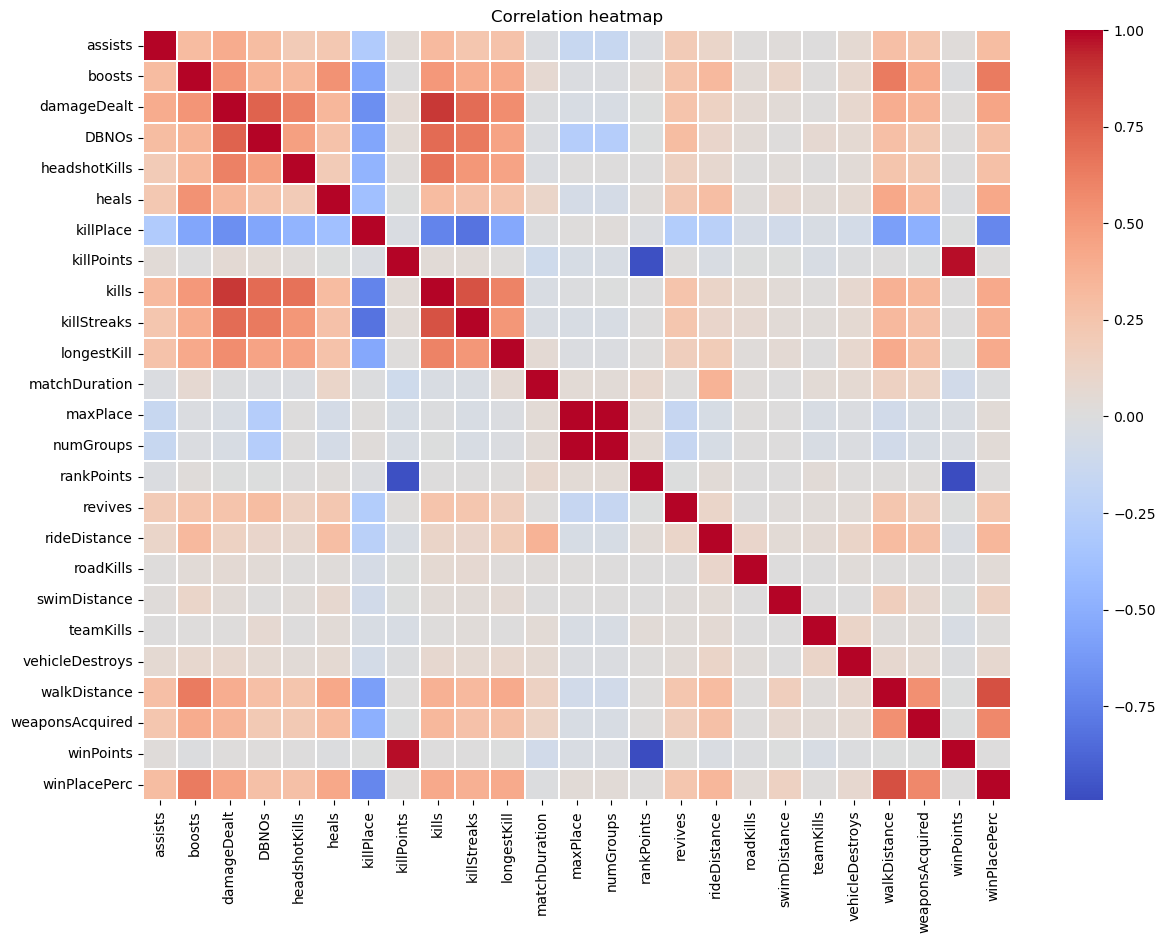

In [8]:
numeric_cols_all = df.select_dtypes(include=np.number).columns.tolist()
corr_cols = [c for c in numeric_cols_all if c != TARGET]
corr = df[corr_cols + [TARGET]].corr(numeric_only=True)

plt.figure(figsize=(14, 10))
sns.heatmap(corr, cmap="coolwarm", center=0, linewidths=0.2)
plt.title("Correlation heatmap")
plt.show()

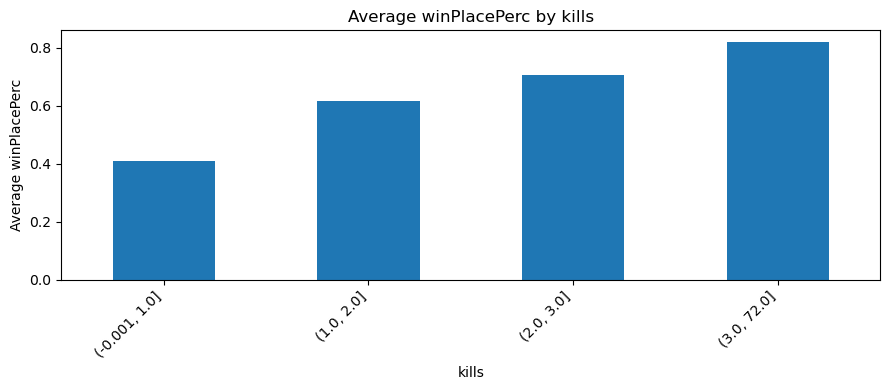

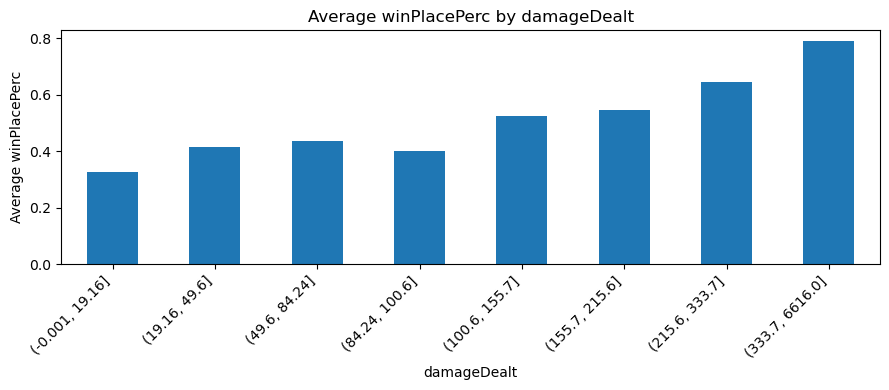

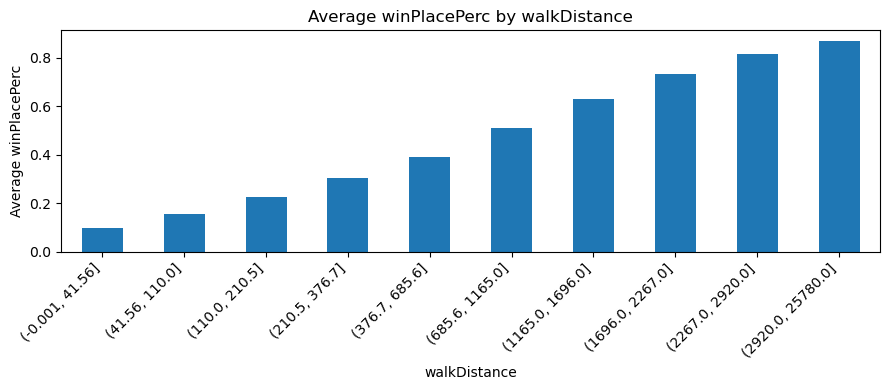

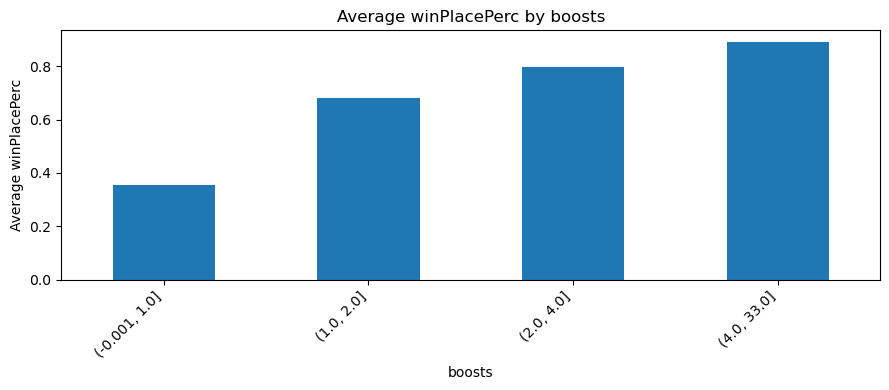

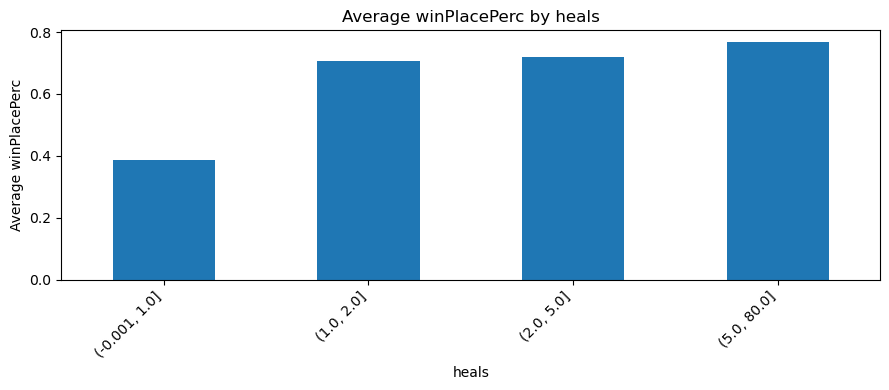

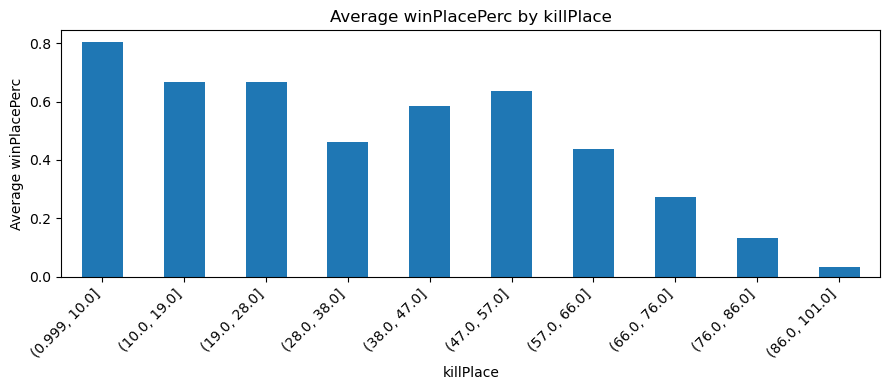

In [9]:
for col in ["kills", "damageDealt", "walkDistance", "boosts", "heals", "killPlace"]:
    if col in df.columns:
        temp = df[[col, TARGET]].copy()
        temp[col] = pd.to_numeric(temp[col], errors="coerce")
        # Bin continuous values to make the trend easier to read.
        temp["bin"] = pd.qcut(temp[col], q=10, duplicates="drop")
        summary = temp.groupby("bin", observed=True)[TARGET].mean()
        plt.figure(figsize=(9, 4))
        summary.plot(kind="bar")
        plt.title(f"Average winPlacePerc by {col}")
        plt.ylabel("Average winPlacePerc")
        plt.xlabel(col)
        plt.xticks(rotation=45, ha="right")
        plt.tight_layout()
        plt.show()

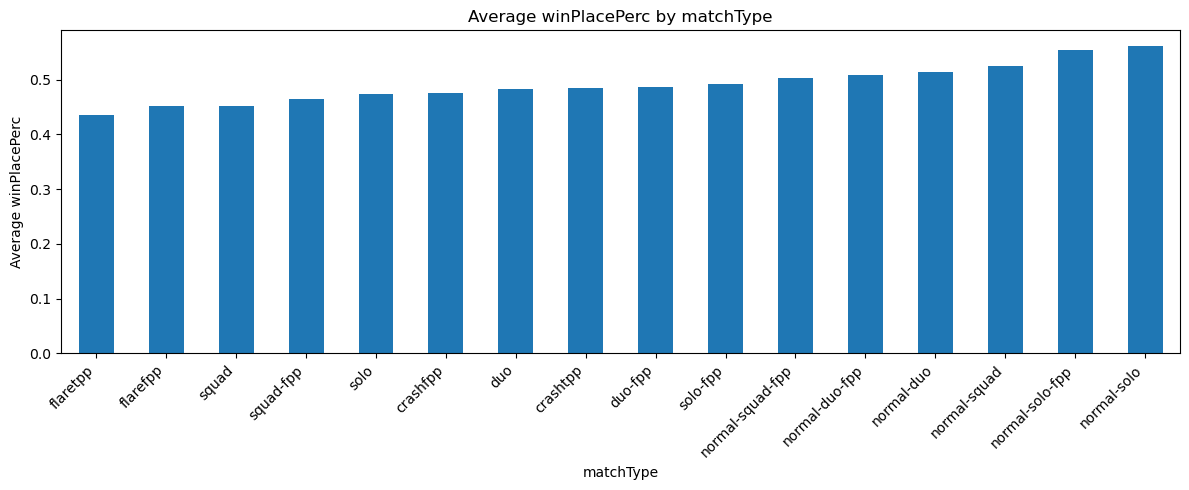

In [10]:
if "matchType" in df.columns:
    plt.figure(figsize=(12, 5))
    df.groupby("matchType")[TARGET].mean().sort_values().plot(kind="bar")
    plt.title("Average winPlacePerc by matchType")
    plt.ylabel("Average winPlacePerc")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

## 6. Prepare features and target

`Id`, `groupId`, and `matchId` are identifiers and are not used as ordinary model features. `matchId` is used only to keep players from the same match together when splitting the data, reducing overly optimistic validation caused by match-level overlap.

If your file does not contain `matchId`, the notebook uses a normal random split.

In [24]:

df = df.replace([np.inf, -np.inf], np.nan)

groups = df["matchId"].astype(str) if "matchId" in df.columns else None

drop_cols = [TARGET]
for col in ["Id", "groupId", "matchId"]:
    if col in df.columns:
        drop_cols.append(col)

X = df.drop(columns=drop_cols, errors="ignore").copy()
y = df[TARGET].astype(float).copy()

categorical_features = X.select_dtypes(include=["object", "category"]).columns.tolist()
numeric_features = [c for c in X.columns if c not in categorical_features]

print("Feature count:", X.shape[1])
print("Numeric features:", len(numeric_features))
print("Categorical features:", categorical_features)
print("Target range:", y.min(), "to", y.max())

Feature count: 25
Numeric features: 24
Categorical features: ['matchType']
Target range: 0.0 to 1.0


## 7. Create training and testing sets

The original PUBG dataset can be very large. For a practical laptop/Jupyter run, this notebook samples up to 200,000 rows before splitting. Increase `MAX_ROWS` if your computer has enough RAM, or set it to `None` to use all rows.

The split is grouped by `matchId` when that column is available.

In [12]:
MAX_ROWS = 200_000  
if MAX_ROWS is not None and len(X) > MAX_ROWS:
    rng = np.random.RandomState(RANDOM_STATE)
    sampled_idx = rng.choice(X.index.to_numpy(), size=MAX_ROWS, replace=False)
    X = X.loc[sampled_idx].copy()
    y = y.loc[sampled_idx].copy()
    if groups is not None:
        groups = groups.loc[sampled_idx].copy()

if groups is not None:
    splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=RANDOM_STATE)
    train_idx, test_idx = next(splitter.split(X, y, groups=groups))
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
else:
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, random_state=RANDOM_STATE
    )

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (159914, 25)
Testing shape: (40086, 25)


## 8. Preprocessing

In [13]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=10))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

print("Preprocessing pipeline is ready.")

Preprocessing pipeline is ready.


## 9. Train and compare multiple regression models

In [14]:
# Models are regression models because winPlacePerc is a continuous value from 0 to 1.
models = {
    "Dummy Baseline": DummyRegressor(strategy="mean"),
    "Ridge Regression": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(
        n_estimators=120,
        max_depth=18,
        min_samples_leaf=3,
        n_jobs=-1,
        random_state=RANDOM_STATE
    ),
    "HistGradientBoosting": HistGradientBoostingRegressor(
        max_iter=150,
        learning_rate=0.08,
        max_leaf_nodes=31,
        l2_regularization=0.1,
        random_state=RANDOM_STATE
    )
}

results = []
trained_models = {}

for name, estimator in models.items():
    print(f"Training {name}...")
    pipe = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", estimator)
    ])
    pipe.fit(X_train, y_train)
    predictions = np.clip(pipe.predict(X_test), 0, 1)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })
    trained_models[name] = pipe

comparison = pd.DataFrame(results).sort_values("RMSE").reset_index(drop=True)
display(comparison)

Training Dummy Baseline...
Training Ridge Regression...
Training Random Forest...
Training HistGradientBoosting...


,Model,MAE,RMSE,R2
0,HistGradientBoosting,0.059386,0.082971,0.926479
1,Random Forest,0.061235,0.087303,0.918602
2,Ridge Regression,0.087768,0.120695,0.844426
3,Dummy Baseline,0.266470,0.306001,-0.000010


## 10. Select the best model

In [15]:
best_model_name = comparison.iloc[0]["Model"]
best_model = trained_models[best_model_name]

print("Best model based on lowest test RMSE:", best_model_name)
print(comparison.iloc[0])

Best model based on lowest test RMSE: HistGradientBoosting
Model    HistGradientBoosting
MAE                  0.059386
RMSE                 0.082971
R2                   0.926479
Name: 0, dtype: object


## 11. Actual vs predicted values

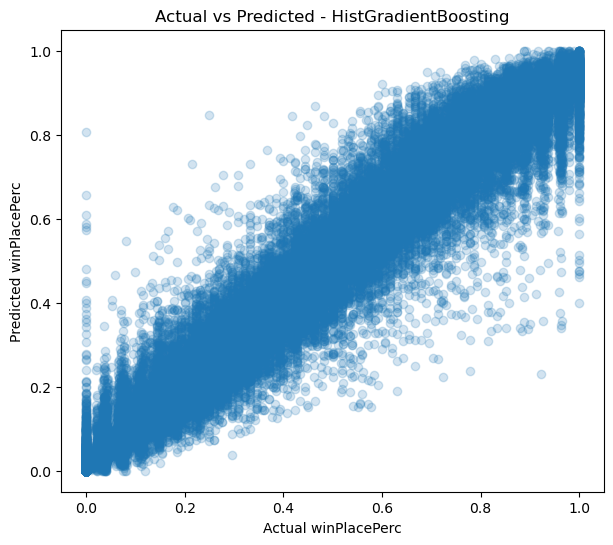

In [18]:
best_predictions = np.clip(best_model.predict(X_test), 0, 1)

plt.figure(figsize=(7, 6))
plt.scatter(y_test, best_predictions, alpha=0.2)
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("Actual winPlacePerc")
plt.ylabel("Predicted winPlacePerc")
plt.title(f"Actual vs Predicted - {best_model_name}")
plt.show()



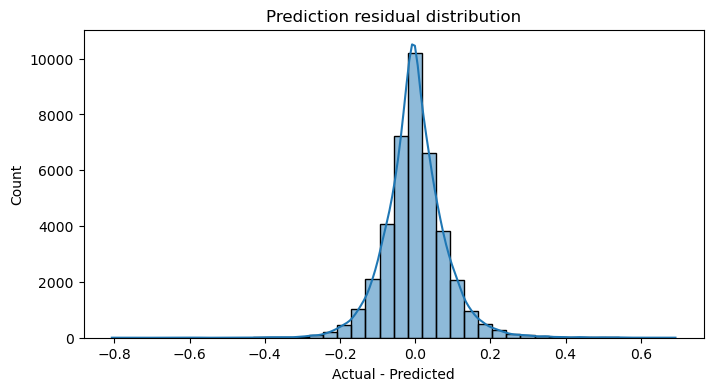

In [17]:
residuals = y_test - best_predictions
plt.figure(figsize=(8, 4))
sns.histplot(residuals, bins=40, kde=True)
plt.title("Prediction residual distribution")
plt.xlabel("Actual - Predicted")
plt.show()

## 12. Important features

Permutation importance is calculated on a manageable sample of the test set. A larger `n_repeats` gives a more stable estimate but takes longer.

Importance measures how much the model's error changes when one feature is shuffled. It indicates predictive usefulness, not proof of cause and effect.

,Feature,Importance
6,killPlace,0.317136
22,walkDistance,0.122510
8,kills,0.119438
12,matchType,0.029427
14,numGroups,0.026809
11,matchDuration,0.014676
13,maxPlace,0.009062
17,rideDistance,0.004510
1,boosts,0.003660
3,DBNOs,0.001497


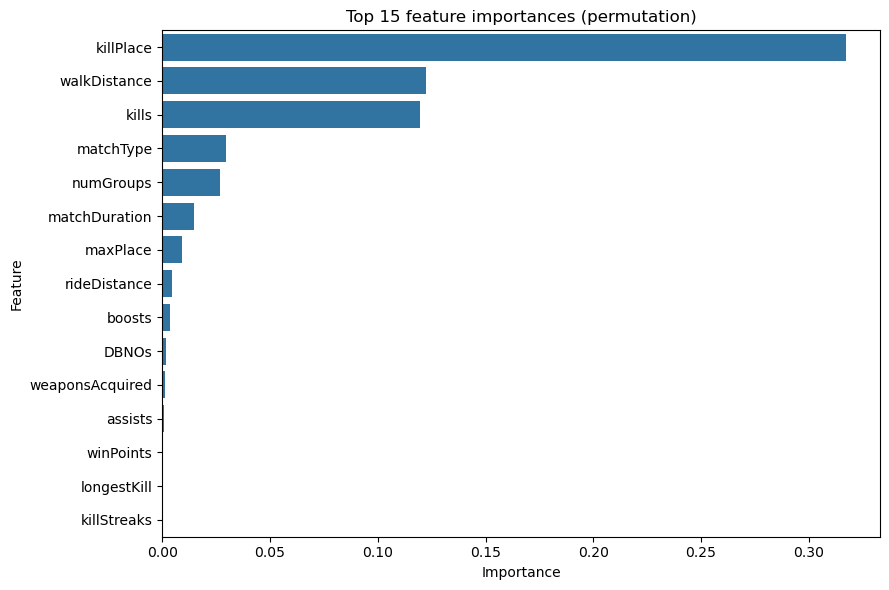

In [19]:
importance_size = min(5000, len(X_test))
X_imp = X_test.sample(n=importance_size, random_state=RANDOM_STATE)
y_imp = y_test.loc[X_imp.index]

perm = permutation_importance(
    best_model,
    X_imp,
    y_imp,
    n_repeats=3,
    random_state=RANDOM_STATE,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X_imp.columns,
    "Importance": perm.importances_mean
}).sort_values("Importance", ascending=False)

display(importance_df.head(15))

plt.figure(figsize=(9, 6))
sns.barplot(data=importance_df.head(15), x="Importance", y="Feature")
plt.title("Top 15 feature importances (permutation)")
plt.tight_layout()
plt.show()

## 13. Predict winPlacePerc for new player data

In [23]:
new_player = X_test.iloc[[0]].copy()
predicted_win_place = float(np.clip(best_model.predict(new_player)[0], 0, 1))
print(f"Predicted winPlacePerc: {predicted_win_place:.4f}")
print(f"Approximate placement percentile: {predicted_win_place * 100:.2f}%")


Predicted winPlacePerc: 0.4515
Approximate placement percentile: 45.15%


## 14. Save the best model

In [21]:
MODEL_PATH = "pubg_winplace_model.joblib"
joblib.dump(best_model, MODEL_PATH)
print("Model saved to:", MODEL_PATH)

Model saved to: pubg_winplace_model.joblib


## 15. Challenges faced and solutions

| Challenge | Technique used | Reason |
|---|---|---|
| Large dataset size | Sample up to 200,000 rows for model comparison | Reduces memory use and training time on a regular laptop |
| Missing values | Median imputation for numeric columns and most-frequent imputation for categorical columns | Allows the models to train without dropping many rows |
| Categorical `matchType` | One-hot encoding | Converts categories into numeric model inputs |
| Identifier columns | Excluded `Id`, `groupId`, and `matchId` from predictors | Prevents models from learning arbitrary ID patterns |
| Players from the same match | Group split using `matchId` | Reduces match-level leakage between training and testing |
| Different feature scales | Standard scaling in the preprocessing pipeline | Helps scale-sensitive models such as Ridge Regression |
| Model selection | Compare MAE, RMSE, and R² | Measures prediction error and goodness of fit |

## 16. Conclusion

This project analyzes PUBG gameplay data and builds regression models to estimate `winPlacePerc`. The notebook compares a baseline model, Ridge Regression, Random Forest, and HistGradientBoosting. The model with the lowest test RMSE is selected as the best candidate in this run.

The top permutation-importance features help identify which gameplay statistics are most useful for prediction. The final production choice should also consider validation performance, inference speed, memory requirements, and testing on fresh match data.

**Important:** `winPlacePerc` is a placement percentile, not a guaranteed probability that a player will win the match. Predictions are estimates based on the dataset and model.

## 17. Final project report output
Run this cell to display the key results for your submission.

In [22]:
print("PUBG GAME WINNER PREDICTION - SUMMARY")
print("=" * 50)
print("Original cleaned data rows:", len(df))
print("Rows used for modeling:", len(X))
print("Number of features:", X.shape[1])
print("\nModel comparison:")
display(comparison)
print("\nRecommended model:", best_model_name)
print("Best model MAE:", round(float(comparison.iloc[0]["MAE"]), 4))
print("Best model RMSE:", round(float(comparison.iloc[0]["RMSE"]), 4))
print("Best model R2:", round(float(comparison.iloc[0]["R2"]), 4))
print("\nTop 10 important features:")
display(importance_df.head(10))

PUBG GAME WINNER PREDICTION - SUMMARY
Original cleaned data rows: 4446965
Rows used for modeling: 200000
Number of features: 25

Model comparison:


,Model,MAE,RMSE,R2
0,HistGradientBoosting,0.059386,0.082971,0.926479
1,Random Forest,0.061235,0.087303,0.918602
2,Ridge Regression,0.087768,0.120695,0.844426
3,Dummy Baseline,0.266470,0.306001,-0.000010



Recommended model: HistGradientBoosting
Best model MAE: 0.0594
Best model RMSE: 0.083
Best model R2: 0.9265

Top 10 important features:


,Feature,Importance
6,killPlace,0.317136
22,walkDistance,0.122510
8,kills,0.119438
12,matchType,0.029427
14,numGroups,0.026809
11,matchDuration,0.014676
13,maxPlace,0.009062
17,rideDistance,0.004510
1,boosts,0.003660
3,DBNOs,0.001497
